# Implementación Paralela con CUDA

Este cuaderno corresponde a los pasos 3, 4 y 5 del proyecto. Primero identifica, con base en las mediciones del cuaderno anterior, qué operaciones conviene paralelizar. Después describe el diseño paralelo y lo implementa en dos fases separadas.

1. **Preparación de datos en varios núcleos del CPU.** La lectura, el redimensionado y la normalización de imágenes se reparten entre varios procesos.
2. **Entrenamiento del modelo en la GPU.** TensorFlow ejecuta la matemática de la red neuronal con CUDA (la plataforma de cómputo paralelo de NVIDIA) y cuDNN (su librería de operaciones para redes neuronales).

Además, se incluye un experimento de contraste. Un kernel propio (una función que se ejecuta en paralelo sobre miles de hilos de la GPU), escrito con Numba, redimensiona las imágenes en la GPU. Así se evalúa si conviene mover también la preparación de datos a la GPU.

## Configuración del Entorno

En este cuaderno la GPU queda visible. La opción de crecimiento de memoria hace que TensorFlow reserve memoria de la GPU solo cuando la necesita, para que Numba también pueda usarla.

In [1]:
import os
import sys
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from src import config
from src.data.make_dataset import class_names, make_dataset
from src.features.build_features import preprocess_sequential
from src.features.parallel_features import decode_parallel, make_pool, preprocess_parallel, split_chunks
from src.models.train_model import (build_cnn, device_name, enable_memory_growth, evaluate,
                                    host_to_device_seconds, set_seed, train)
from src.utils.monitor import ResourceMonitor
from src.utils.system_info import print_report
from src.utils.timing import Timer, save_times, summarize

enable_memory_growth()
print("Dispositivo de TensorFlow:", device_name())

I0000 00:00:1795033512.678614   30347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795033515.002432   30347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Dispositivo de TensorFlow: GPU


In [2]:
print_report(include_nvidia_smi=True)

Sistema operativo       Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
Python                  3.12.16
CPU                     13th Gen Intel(R) Core(TM) i9-13980HX
Núcleos físicos         16
Núcleos lógicos         32
RAM total (GB)          7.6
TensorFlow              2.21.0
Compilado con CUDA      12.5.1
Compilado con cuDNN     9
GPU visibles para TF    /physical_device:GPU:0
CUDA_VISIBLE_DEVICES    (sin definir)

Wed Nov 18 14:25:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 620.73.02              KMD Version: 621.24        CUDA UMD Version: 13.5     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |    

TensorFlow detecta la GPU NVIDIA GeForce RTX 4050 para portátiles, que tiene 6,141 MiB de memoria. Antes de iniciar las mediciones, la GPU no tiene procesos activos y su uso es de 0 %.

## Identificación de Oportunidades de Paralelización

La siguiente celda recupera los tiempos de la solución secuencial y calcula qué porcentaje del tiempo total ocupa cada fase y cada etapa del preprocesamiento.

In [3]:
seq_times = pd.read_csv(config.RESULTS_DIR / "sequential_times.csv")
seq_mean = seq_times[seq_times["note"] != "first"].groupby("phase", sort=False)["seconds"].mean()
share = pd.DataFrame({"segundos": seq_mean, "porcentaje": 100 * seq_mean / seq_mean.sum()})
display(share.round(2))

stages = pd.read_csv(config.RESULTS_DIR / "01_preprocess_stages.csv", index_col="etapa")
stages.round(3)

,segundos,porcentaje
phase,,
preprocess,11.53,11.63
train,86.75,87.52
inference,0.84,0.84


,segundos,porcentaje,ms por imagen
etapa,,,
read,6.495,60.431,0.448
resize,4.053,37.706,0.279
normalize,0.200,1.863,0.014


En la solución secuencial, el entrenamiento ocupa el 87.5 % del tiempo, el preprocesamiento el 11.6 % y la inferencia el 0.8 %. A partir de estos resultados se seleccionan dos operaciones para paralelizar.

1. **Preparación de datos.** Cada imagen se lee, se redimensiona y se normaliza sin depender de las demás. La lectura y el redimensionado suman el 98 % de esta fase y hoy usan un solo núcleo del CPU. Como la lectura implica abrir archivos y descomprimir JPEG, tareas propias del CPU, esta fase se reparte entre los núcleos del CPU.
2. **Entrenamiento del modelo.** Las convoluciones concentran el 97.5 % de las multiplicaciones-acumulaciones, y cada una consiste en millones de multiplicaciones independientes entre sí. Este tipo de cálculo es el que mejor aprovecha los miles de núcleos de una GPU, por lo que el entrenamiento se delega a la GPU con CUDA.

La inferencia usa las mismas operaciones de la red, de modo que también se ejecuta en la GPU, aunque su peso en el tiempo total es pequeño.

## Diseño del Algoritmo Paralelo

### Fase 1 en el CPU

Cada imagen se procesa de forma independiente, por lo que el problema es de paralelismo de datos (la misma operación se aplica a muchos datos distintos sin que unos dependan de otros). Las 14,500 rutas se dividen en bloques contiguos, cuatro bloques por proceso, para equilibrar la carga. Cada proceso lee y redimensiona su bloque, y devuelve un arreglo de enteros de 8 bits. El proceso principal une los bloques y normaliza todo el arreglo en una sola operación vectorizada (una operación que NumPy aplica a todo el arreglo a la vez).

Se usan procesos y no hilos porque el intérprete de Python tiene un candado global (GIL, Global Interpreter Lock) que impide que varios hilos ejecuten código Python al mismo tiempo.

### Fase 2 en la GPU

TensorFlow divide cada época en lotes de 64 imágenes. Cada lote se copia a la memoria de la GPU, y cuDNN lanza los kernels de convolución, activación y agrupamiento. En estos kernels miles de hilos calculan en paralelo los elementos de los mapas de activación. La distribución en hilos, bloques y grid la decide cuDNN de forma automática según el tamaño de cada capa.

### Experimento con un Kernel Propio

Para el redimensionado en la GPU se diseña un kernel en el que cada hilo calcula un píxel de salida con sus tres canales. Los hilos se agrupan en bloques de 16 × 16 (256 hilos), y cada bloque cubre una región de 16 × 16 píxeles de la imagen de salida. El grid tiene 4 × 4 bloques por imagen en los ejes x e y, y una capa por imagen en el eje z. La siguiente celda calcula estas dimensiones para un lote.

In [4]:
from src.features.cuda_kernels import BLOCK, grid_dims

grid = grid_dims(config.GPU_CHUNK)
threads_per_block = BLOCK[0] * BLOCK[1] * BLOCK[2]
n_blocks = grid[0] * grid[1] * grid[2]
pd.Series({
    "Imágenes por lote": config.GPU_CHUNK,
    "Bloque (x, y, z)": BLOCK,
    "Grid (x, y, z)": grid,
    "Hilos por bloque": threads_per_block,
    "Bloques por lote": n_blocks,
    "Hilos por lote": n_blocks * threads_per_block,
}).to_frame("valor")

,valor
Imágenes por lote,2048
"Bloque (x, y, z)","(16, 16, 1)"
"Grid (x, y, z)","(4, 4, 2048)"
Hilos por bloque,256
Bloques por lote,32768
Hilos por lote,8388608


Un lote de 2,048 imágenes, el tamaño máximo configurado, se procesa con 32,768 bloques de 256 hilos, es decir, más de 8.3 millones de hilos, uno por cada píxel de salida. En la ejecución, las 14,500 imágenes se reparten en 8 lotes de cerca de 1,813 imágenes cada uno.

## Implementación y Medición

### Fase 1 con Varios Procesos del CPU

Primero se ejecuta la versión secuencial una vez, como referencia para comprobar que la versión paralela produce exactamente el mismo resultado. Esta ejecución también carga los archivos en la caché del sistema operativo, de modo que todas las mediciones parten de las mismas condiciones. Luego se mide el preprocesamiento con 1, 2, 4, 8, 16 y 32 procesos, con 5 repeticiones cada uno. Antes de las repeticiones se hace una ejecución de calentamiento, que no se promedia, para que los procesos ya estén iniciados.

In [5]:
manifest = make_dataset()
classes = class_names(manifest)
paths = manifest["path"].tolist()

with Timer() as t_ref:
    X_ref = preprocess_sequential(paths)
print(f"Referencia secuencial: {t_ref.elapsed:.2f} s")

worker_counts = [n for n in config.WORKER_COUNTS if n <= os.cpu_count()]
print("Configuraciones de procesos:", worker_counts)

Referencia secuencial: 20.28 s
Configuraciones de procesos: [1, 2, 4, 8, 16, 32]


In [6]:
cpu_records = []
cpu_usage_par = None

for n in worker_counts:
    with Timer() as t_start:
        pool = make_pool(n)
        X_par = preprocess_parallel(paths, pool, n)
    cpu_records.append({"phase": "preprocess", "workers": n, "rep": 0, "seconds": t_start.elapsed, "note": "warmup"})
    assert np.array_equal(X_par, X_ref), "El resultado paralelo difiere del secuencial"

    monitor = ResourceMonitor(interval=0.25)
    with monitor:
        for rep in range(1, config.N_REPS_PREPROCESS + 1):
            with Timer() as t:
                X_par = preprocess_parallel(paths, pool, n)
            cpu_records.append({"phase": "preprocess", "workers": n, "rep": rep, "seconds": t.elapsed, "note": ""})
    pool.close()
    pool.join()
    if n == worker_counts[-1]:
        cpu_usage_par = monitor.to_dataframe()

    reps = [r["seconds"] for r in cpu_records if r["workers"] == n and r["rep"] > 0]
    print(f"{n:>2} procesos: {np.mean(reps):.2f} s en promedio (calentamiento {t_start.elapsed:.2f} s)")

cpu_df = save_times(cpu_records, config.RESULTS_DIR / "02_cpu_parallel_times.csv")
cpu_usage_par.to_csv(config.RESULTS_DIR / "02_cpu_usage_parallel.csv", index=False)

 1 procesos: 14.28 s en promedio (calentamiento 13.53 s)


 2 procesos: 8.16 s en promedio (calentamiento 10.55 s)


 4 procesos: 4.60 s en promedio (calentamiento 4.26 s)


 8 procesos: 2.67 s en promedio (calentamiento 3.26 s)


16 procesos: 1.83 s en promedio (calentamiento 2.38 s)


32 procesos: 1.81 s en promedio (calentamiento 3.01 s)


In [7]:
cpu_summary = pd.DataFrame({
    n: summarize(g.loc[g["rep"] > 0, "seconds"].tolist()) for n, g in cpu_df.groupby("workers")
}).T.rename_axis("procesos").round(3)
cpu_summary

,n,mean,std,min,max
procesos,,,,,
1,5.0,14.283,1.142,13.073,15.671
2,5.0,8.164,0.904,6.763,9.278
4,5.0,4.600,0.436,4.164,5.316
8,5.0,2.672,0.574,2.101,3.603
16,5.0,1.827,0.188,1.619,2.087
32,5.0,1.813,0.330,1.476,2.340


En todas las configuraciones el resultado es idéntico al de la versión secuencial, porque la comprobación con `np.array_equal` no falló. La referencia secuencial tardó 20.28 s porque incluye la primera lectura de los archivos desde el disco.

El tiempo baja de 14.28 s con 1 proceso a 1.81 s con 32 procesos. La mejora es casi proporcional hasta 8 procesos y luego se reduce. Entre 16 y 32 procesos el tiempo prácticamente no cambia (1.83 s frente a 1.81 s). Esto coincide con los 16 núcleos físicos del equipo, ya que los 32 núcleos lógicos comparten los recursos de cálculo en pares mediante hyperthreading (técnica que permite a un núcleo físico atender dos hilos a la vez).

Con un solo proceso, la versión paralela tarda más que la secuencial (14.28 s frente a 11.53 s). Esta diferencia corresponde al costo adicional de coordinar el pool y transferir los resultados entre procesos, que la versión secuencial no tiene.

### Experimento de Contraste con el Kernel de Numba

En esta variante el CPU solo lee y decodifica las imágenes (con todos los procesos), y la GPU realiza el redimensionado y la normalización. El trabajo se divide en lotes de hasta 2,048 imágenes. Para cada lote se mide por separado la decodificación en el CPU, la copia de las imágenes originales de 200 × 200 a la GPU, la ejecución del kernel y la copia del resultado de vuelta al CPU. La primera llamada al kernel incluye su compilación, por lo que se mide aparte.

In [8]:
from src.features.cuda_kernels import resize_normalize_gpu

n_workers = worker_counts[-1]
chunks = split_chunks(paths, int(np.ceil(len(paths) / config.GPU_CHUNK)))
pool = make_pool(n_workers)
sample = decode_parallel(chunks[0][:n_workers], pool, n_workers)

with Timer() as t_compile:
    resize_normalize_gpu(sample)
print(f"Compilación y primera llamada del kernel: {t_compile.elapsed:.2f} s")

numba_records = []
for rep in range(0, config.N_REPS_PREPROCESS + 1):
    totals = {"decode": 0.0, "h2d": 0.0, "kernel": 0.0, "d2h": 0.0}
    abs_diff_sum, abs_diff_max, start = 0.0, 0.0, 0
    for chunk in chunks:
        with Timer() as t_dec:
            raw = decode_parallel(chunk, pool, n_workers)
        X_chunk, times = resize_normalize_gpu(raw)
        totals["decode"] += t_dec.elapsed
        for key, value in times.items():
            totals[key] += value
        diff = np.abs(X_chunk - X_ref[start:start + len(chunk)])
        abs_diff_sum, abs_diff_max = abs_diff_sum + diff.sum(), max(abs_diff_max, diff.max())
        start += len(chunk)
    total = sum(totals.values())
    numba_records.append({"rep": rep, **totals, "total": total, "note": "warmup" if rep == 0 else ""})
    print(f"Repetición {rep}: total {total:.2f} s " + ", ".join(f"{k} {v:.3f} s" for k, v in totals.items()))

pool.close()
pool.join()

print(f"Diferencia con la versión de PIL: media {abs_diff_sum / X_ref.size:.4f}, máxima {abs_diff_max:.4f}")
print(f"Datos copiados a la GPU por repetición: {len(paths) * 200 * 200 * 3 / 1024**2:.0f} MB")

numba_df = save_times(numba_records, config.RESULTS_DIR / "02_numba_times.csv")
numba_df[numba_df["rep"] > 0].drop(columns=["rep", "note"]).agg(["mean", "std"]).round(4)

Compilación y primera llamada del kernel: 0.76 s


Repetición 0: total 6.98 s decode 6.284 s, h2d 0.378 s, kernel 0.056 s, d2h 0.262 s


Repetición 1: total 8.44 s decode 7.286 s, h2d 0.675 s, kernel 0.151 s, d2h 0.330 s


Repetición 2: total 7.89 s decode 6.662 s, h2d 0.635 s, kernel 0.147 s, d2h 0.447 s


Repetición 3: total 8.41 s decode 7.231 s, h2d 0.595 s, kernel 0.134 s, d2h 0.450 s


Repetición 4: total 8.28 s decode 6.999 s, h2d 0.705 s, kernel 0.144 s, d2h 0.433 s


Repetición 5: total 7.64 s decode 6.408 s, h2d 0.661 s, kernel 0.177 s, d2h 0.397 s
Diferencia con la versión de PIL: media 0.0143, máxima 0.4561
Datos copiados a la GPU por repetición: 1659 MB


,decode,h2d,kernel,d2h,total
mean,6.9172,0.6543,0.1507,0.4112,8.1334
std,0.3762,0.0415,0.0160,0.0503,0.3512


El kernel redimensiona y normaliza las 14,500 imágenes en 0.15 s, mientras que el redimensionado secuencial en el CPU tarda 4.05 s. Sin embargo, la variante completa tarda 8.13 s en promedio, más de cuatro veces lo que tarda el preprocesamiento con 32 procesos (1.81 s).

- **Decodificación (6.92 s).** Es la etapa más lenta, porque cada proceso debe devolver las imágenes completas de 200 × 200 (1,659 MB en total) en lugar de las reducidas de 64 × 64, que ocupan casi 10 veces menos.
- **Copias entre el CPU y la GPU (1.07 s).** La copia hacia la GPU y la copia de regreso suman siete veces el tiempo del kernel.
- **Compilación.** La primera llamada del kernel tardó 0.76 s adicionales.

La diferencia media de 0.0143 frente a la versión de PIL se debe a que PIL suaviza la imagen al reducirla, mientras que el kernel usa interpolación bilineal simple.

En conjunto, el cálculo en la GPU es muy rápido, pero mover los datos cuesta más de lo que se ahorra. Este resultado justifica mantener la preparación de datos en el CPU.

### Fase 2 con la GPU

El entrenamiento usa exactamente el mismo modelo, los mismos datos, la misma semilla, 10 épocas y lotes de 64 imágenes que la versión secuencial. Los datos de entrada son los que produjo la Fase 1. Dentro del tiempo de entrenamiento ya se incluyen las copias de cada lote del CPU a la GPU. Además, se mide aparte cuánto tarda copiar todo el conjunto de entrenamiento a la GPU. Durante el entrenamiento se registra el uso de la GPU y de su memoria con `nvidia-smi`.

In [9]:
y_all = manifest["label_idx"].to_numpy()
masks = {s: (manifest["split"] == s).to_numpy() for s in ("train", "val", "test")}
X_train, y_train = X_par[masks["train"]], y_all[masks["train"]]
X_val, y_val = X_par[masks["val"]], y_all[masks["val"]]
X_test, y_test = X_par[masks["test"]], y_all[masks["test"]]
del X_ref

gpu_records, gpu_epochs = [], []
gpu_usage = None

for rep in range(1, config.N_REPS_TRAIN + 1):
    t_h2d = host_to_device_seconds(X_train)
    set_seed()
    model = build_cnn(n_classes=len(classes))
    with ResourceMonitor(interval=0.5, gpu=True) as mon:
        result = train(model, X_train, y_train, X_val, y_val)
    test_loss, test_acc, t_inf = evaluate(model, X_test, y_test)

    gpu_records += [
        {"phase": "transfer_h2d", "device": "GPU", "rep": rep, "seconds": t_h2d},
        {"phase": "train", "device": "GPU", "rep": rep, "seconds": result.total_time},
        {"phase": "inference", "device": "GPU", "rep": rep, "seconds": t_inf},
    ]
    for epoch, sec in enumerate(result.epoch_times, start=1):
        gpu_epochs.append({
            "device": "GPU", "rep": rep, "epoch": epoch, "seconds": sec,
            "train_acc": result.history["accuracy"][epoch - 1],
            "val_acc": result.history["val_accuracy"][epoch - 1],
        })
    if gpu_usage is None:
        gpu_usage = mon.to_dataframe()
    print(f"Repetición {rep}: entrenamiento {result.total_time:.1f} s, accuracy de prueba {test_acc:.4f}, "
          f"inferencia {t_inf:.2f} s, copia a la GPU {t_h2d:.3f} s")

gpu_df = save_times(gpu_records, config.RESULTS_DIR / "gpu_times.csv")
gpu_epochs_df = save_times(gpu_epochs, config.RESULTS_DIR / "gpu_epochs.csv")
gpu_usage.to_csv(config.RESULTS_DIR / "02_gpu_usage_train.csv", index=False)
print(f"Tamaño de X_train: {X_train.nbytes / 1024**2:.1f} MB")

Epoch 1/10


159/159 - 30s - 191ms/step - accuracy: 0.1952 - loss: 2.7889 - val_accuracy: 0.3664 - val_loss: 2.0687


Epoch 2/10


159/159 - 2s - 14ms/step - accuracy: 0.5662 - loss: 1.3831 - val_accuracy: 0.6984 - val_loss: 0.9538


Epoch 3/10


159/159 - 2s - 14ms/step - accuracy: 0.7487 - loss: 0.7762 - val_accuracy: 0.8230 - val_loss: 0.5808


... (53 outputs left out)

159/159 - 2s - 14ms/step - accuracy: 0.9488 - loss: 0.1552 - val_accuracy: 0.9223 - val_loss: 0.2490


Epoch 10/10


159/159 - 2s - 14ms/step - accuracy: 0.9541 - loss: 0.1379 - val_accuracy: 0.9471 - val_loss: 0.1649


Repetición 3: entrenamiento 34.8 s, accuracy de prueba 0.9416, inferencia 0.45 s, copia a la GPU 0.958 s
Tamaño de X_train: 475.8 MB


En la GPU, el modelo alcanza entre 93.6 % y 94.4 % de accuracy de prueba, un valor similar al 94.8 % del CPU. A diferencia del CPU, las repeticiones no son idénticas aunque usen la misma semilla, porque algunas operaciones de cuDNN no son deterministas (el orden en que suman los resultados parciales varía entre ejecuciones). Copiar el conjunto de entrenamiento completo (475.8 MB) a la GPU tarda entre 0.96 s y 1.32 s.

In [10]:
gpu_summary = pd.DataFrame({
    phase: summarize(g["seconds"].tolist()) for phase, g in gpu_df.groupby("phase", sort=False)
}).T.round(3)
display(gpu_summary)
gpu_epochs_df.pivot(index="epoch", columns="rep", values="seconds").round(2)

,n,mean,std,min,max
transfer_h2d,3.0,1.155,0.181,0.958,1.315
train,3.0,40.271,9.361,34.759,51.080
inference,3.0,0.490,0.051,0.447,0.546


rep,1,2,3
epoch,,,
1,30.31,14.05,14.16
2,2.23,2.43,2.39
3,2.23,2.23,2.19
4,2.18,2.22,2.22
5,2.20,2.19,2.21
6,2.22,2.21,2.23
7,2.22,2.24,2.25
8,2.20,2.21,2.22
9,2.17,2.19,2.19


El entrenamiento en la GPU tarda 40.27 s en promedio. Su desviación estándar es alta (9.36 s) por la primera repetición, que tardó 51.08 s. En esa repetición la primera época duró 30.31 s, y en las otras dos cerca de 14 s. En cada repetición TensorFlow compila las operaciones del modelo nuevo para la GPU, y en la primera además carga las librerías de CUDA y cuDNN. Desde la segunda época, cada época tarda cerca de 2.2 s, frente a 8.4 s en el CPU. La inferencia baja de 0.84 s a 0.49 s.

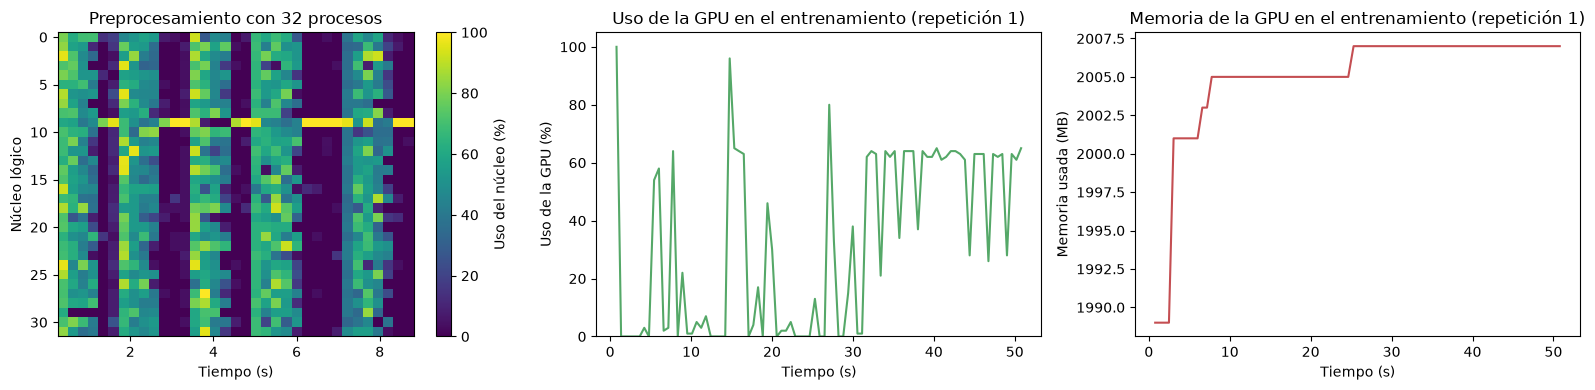

Uso promedio del CPU con 32 procesos: 34.3 %
Uso promedio de la GPU en el entrenamiento: 32.6 %
Memoria máxima usada en la GPU: 2007 MB


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

cores = cpu_usage_par.filter(like="cpu_").T
im = axes[0].imshow(cores, aspect="auto", cmap="viridis", vmin=0, vmax=100,
                    extent=[cpu_usage_par["t"].min(), cpu_usage_par["t"].max(), len(cores) - 0.5, -0.5])
axes[0].set_title(f"Preprocesamiento con {worker_counts[-1]} procesos")
axes[0].set_xlabel("Tiempo (s)")
axes[0].set_ylabel("Núcleo lógico")
fig.colorbar(im, ax=axes[0], label="Uso del núcleo (%)")

axes[1].plot(gpu_usage["t"], gpu_usage["gpu_util"], color="#55A868")
axes[1].set_title("Uso de la GPU en el entrenamiento (repetición 1)")
axes[1].set_xlabel("Tiempo (s)")
axes[1].set_ylabel("Uso de la GPU (%)")
axes[1].set_ylim(0, 105)

axes[2].plot(gpu_usage["t"], gpu_usage["gpu_mem_mb"], color="#C44E52")
axes[2].set_title("Memoria de la GPU en el entrenamiento (repetición 1)")
axes[2].set_xlabel("Tiempo (s)")
axes[2].set_ylabel("Memoria usada (MB)")

fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_resource_usage.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Uso promedio del CPU con {worker_counts[-1]} procesos: {cores.mean().mean():.1f} %")
print(f"Uso promedio de la GPU en el entrenamiento: {gpu_usage['gpu_util'].mean():.1f} %")
print(f"Memoria máxima usada en la GPU: {gpu_usage['gpu_mem_mb'].max():.0f} MB")

Con 32 procesos, todos los núcleos lógicos trabajan al mismo tiempo durante el preprocesamiento. El uso promedio es de 34.3 % porque el intervalo medido incluye franjas oscuras, en las que solo un núcleo trabaja al 100 %. Esas franjas corresponden a la parte que ejecuta únicamente el proceso principal, que une los bloques y normaliza el resultado.

En la GPU, el uso es irregular durante los primeros 30 s, que corresponden a la preparación de la primera época, y después se estabiliza entre 60 % y 65 %. La memoria usada llega a 2,007 MB de los 6,141 MB disponibles. Este uso parcial indica que un modelo de este tamaño, con lotes de 64 imágenes, no alcanza a ocupar todos los núcleos de la GPU.